# Лабораторная работа №2: классификация

**Задача:** по данным о пассажире Титаника предсказать, выжил он (`Survived = 1`) или нет (`0`).
**Данные:** Titanic Dataset (Kaggle), 891 пассажир.
**Метрика:** F1-score для класса 1 (основная), а также Accuracy, Precision, Recall. Требование — F1 > 0.70.

## 0. Импорты

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42          # фиксируем случайность, чтобы результат воспроизводился
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Загрузка данных

Файл `Titanic-Dataset.csv` (https://www.kaggle.com/datasets/yasserh/titanic-dataset) лежит в папке `data/`.

In [2]:
df = pd.read_csv("data/Titanic-Dataset.csv")
print(df.shape)
df.head()

(891, 12)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Что означают столбцы:
- `PassengerId` — номер пассажира, `Name` — имя, `Ticket` — номер билета, `Cabin` — номер каюты;
- `Pclass` — класс билета (1 — первый, самый дорогой), `Fare` — цена билета;
- `Sex` — пол, `Age` — возраст;
- `SibSp` — сколько братьев/сестёр/супругов на борту, `Parch` — сколько родителей/детей на борту;
- `Embarked` — порт посадки (S, C, Q);
- `Survived` — **целевая переменная**.

## 2. Первичный анализ данных

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

In [4]:
print("Пропуски по столбцам:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nПолных дубликатов строк:", df.duplicated().sum())
print("\nУникальных значений:")
print(df[["PassengerId", "Name", "Ticket", "Cabin"]].nunique())

Пропуски по столбцам:
Age         177
Cabin       687
Embarked      2
dtype: int64

Полных дубликатов строк: 0

Уникальных значений:
PassengerId    891
Name           891
Ticket         681
Cabin          147
dtype: int64

**Вывод.**
- Пропуски есть в трёх столбцах: у возраста (`Age`) — заметная часть, у каюты (`Cabin`) — почти у всех, у порта (`Embarked`) — единицы. Их надо будет заполнить или убрать.
- Дубликатов нет.
- `PassengerId` и `Name` уникальны у каждого пассажира, у `Ticket` и `Cabin` тоже почти все значения разные. Это не признаки, а «паспорт» пассажира: модель по ним просто запомнит, кто выжил, и ничему полезному не научится. Поэтому их **не используем**.

### Целевая переменная

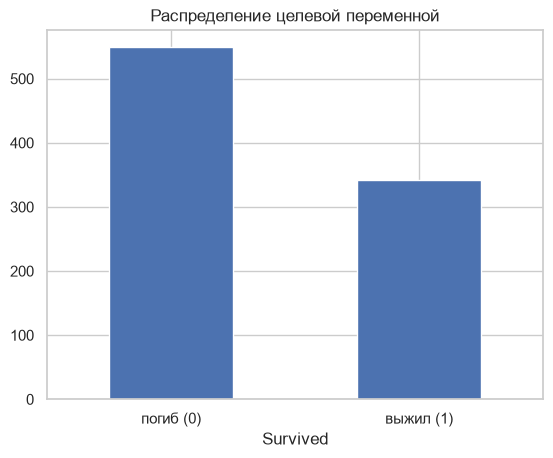

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

In [5]:
ax = df["Survived"].value_counts().plot(kind="bar")
ax.set_xticklabels(["погиб (0)", "выжил (1)"], rotation=0)
plt.title("Распределение целевой переменной")
plt.show()
df["Survived"].value_counts(normalize=True).round(3)

**Вывод.** Погибших больше, чем выживших, примерно в полтора раза. Классы не равны, поэтому одной Accuracy мало:
модель, которая всем говорит «погиб», уже получит неплохую Accuracy, хотя ничего не умеет. Поэтому главная метрика — F1.

### Связь признаков с выживанием

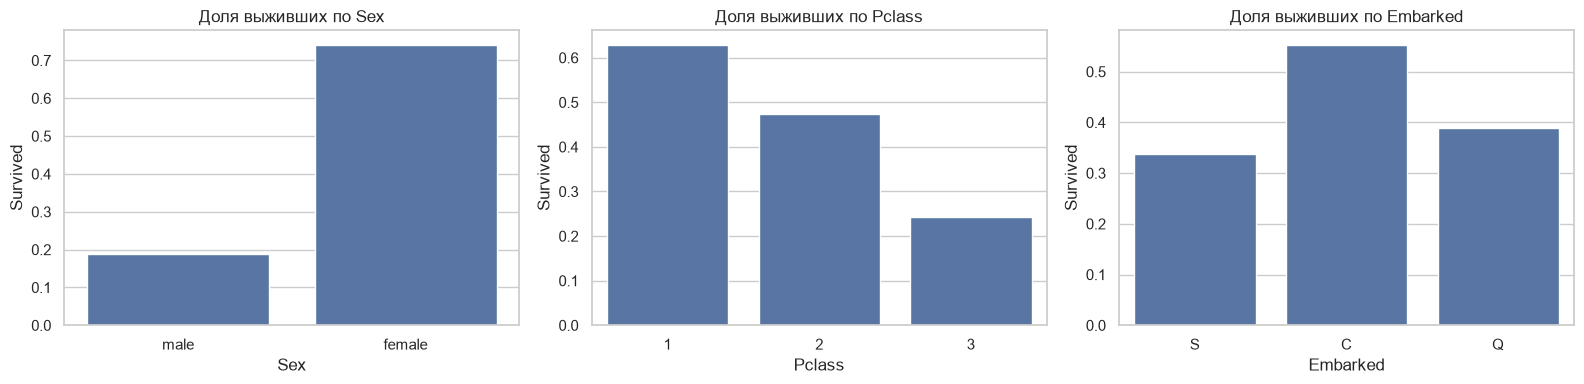

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axs, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=df, x=col, y="Survived", ax=ax, errorbar=None)
    ax.set_title(f"Доля выживших по {col}")
plt.tight_layout(); plt.show()

print(df.groupby("Sex")["Survived"].mean().round(3))
print(df.groupby("Pclass")["Survived"].mean().round(3))

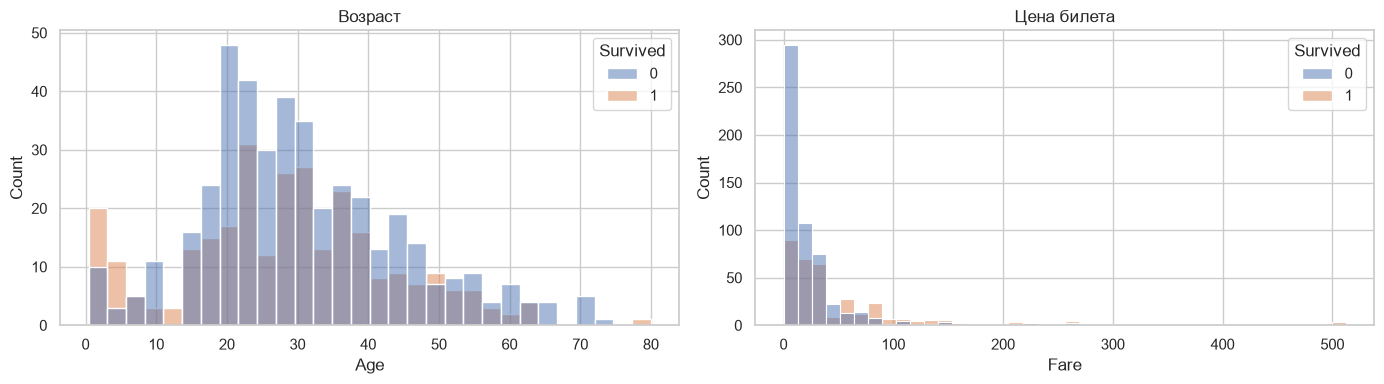

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, ax=axs[0])
axs[0].set_title("Возраст")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axs[1])
axs[1].set_title("Цена билета")
plt.tight_layout(); plt.show()

**Вывод.**
- Главное — **пол**: женщины выживали намного чаще мужчин (правило «сначала женщины и дети»).
- Второе — **класс**: чем выше класс, тем больше шансов выжить. В 3-м классе выжило меньше всего.
- Дети выживали чаще, а у кого дорогой билет — тоже чаще (это связано с классом).
- Значит, ждём, что модели будут считать важными пол, класс, цену билета и возраст.

## 3. Подготовка данных и разбиение

In [8]:
# Новый признак: размер семьи на борту (сам пассажир + родственники)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

num_features = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]   # числовые
cat_features = ["Sex", "Embarked"]                                          # категориальные

X = df[num_features + cat_features]   # PassengerId, Name, Ticket, Cabin не берём
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)
print("Доля выживших в train:", round(y_train.mean(), 3), " в test:", round(y_test.mean(), 3))

train: (712, 8)  test: (179, 8)
Доля выживших в train: 0.383  в test: 0.385

**Что делаем с данными и почему:**
- `Age` — пропуски заполняем **медианой** (она не боится выбросов).
- `Embarked` — 2 пропуска, заполняем **самым частым** значением.
- `Cabin` — пропущено 77%, заполнить нечем, поэтому выкидываем.
- `Sex`, `Embarked` — текст, модели нужны числа. Делаем **One-Hot Encoding**: каждая категория — отдельный столбец из 0 и 1.
- Числовые признаки **масштабируем** (StandardScaler): среднее 0, разброс 1. Это важно для SVM и KNN, которые считают расстояния между объектами. Деревьям масштаб не важен, но и не мешает.
- `stratify=y` — в train и test одинаковая доля выживших.
- Все преобразования собраны в `Pipeline`: медиану, среднее и т.д. они считают **только по train**, поэтому информация из test в обучение не попадает.

In [9]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),      # пропуски -> медиана
        ("scaler", StandardScaler()),                       # масштабирование
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),          # пропуски -> самое частое
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),
    ]), cat_features),
], verbose_feature_names_out=False)

def make_model(clf):
    """Склеиваем предобработку и модель в одну цепочку."""
    return Pipeline([("prep", preprocess), ("model", clf)])

## 4. Метрики и baseline

In [10]:
results = {}   # сюда складываем метрики всех моделей

def evaluate(name, model):
    """Считает метрики на test, F1 на train и рисует confusion matrix."""
    pred = model.predict(X_test)
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "F1 train": f1_score(y_train, model.predict(X_train)),
    }
    print(name, {k: round(v, 3) for k, v in results[name].items()})

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["погиб", "выжил"], cmap="Blues", colorbar=False)
    plt.title(name); plt.gcf().set_size_inches(4, 3.5); plt.show()

Baseline (most frequent) {'Accuracy': 0.615, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'F1 train': 0.0}

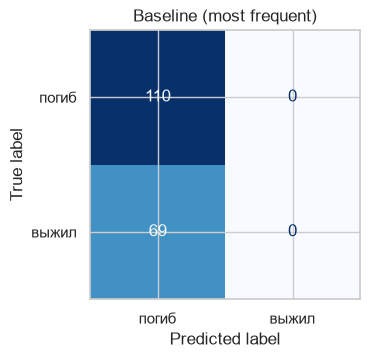

In [11]:
dummy = make_model(DummyClassifier(strategy="most_frequent"))   # всегда предсказывает самый частый класс
dummy.fit(X_train, y_train)
evaluate("Baseline (most frequent)", dummy)

**Как читать confusion matrix** (строки — правда, столбцы — предсказание):
- **TN** (левый верх) — погиб, и модель сказала «погиб»;
- **TP** (правый низ) — выжил, и модель сказала «выжил»;
- **FP** (правый верх) — погиб, а модель сказала «выжил» (ложная тревога);
- **FN** (левый низ) — выжил, а модель сказала «погиб» (пропустили выжившего).

**Метрики:**
- **Accuracy** — доля верных ответов.
- **Precision** — из тех, кого модель назвала выжившими, сколько правда выжило.
- **Recall** — из всех выживших сколько модель нашла.
- **F1** — среднее между Precision и Recall (гармоническое). Высокое, только если оба хорошие.

**Вывод.** Baseline всем говорит «погиб». Accuracy у него вроде бы неплохая, но F1 = 0: ни одного выжившего он не нашёл.
Это показывает, почему Accuracy тут обманчива.

**FP и FN в нашей задаче:** FN — человек выжил, а модель сказала «погиб» (пропустили выжившего).
FP — человек погиб, а модель сказала «выжил» (ложная надежда). Если бы модель помогала спасателям искать выживших,
FN был бы хуже: мы бы перестали искать живого человека.

## 5. Decision Tree (дерево решений)

Decision Tree {'Accuracy': 0.777, 'Precision': 0.71, 'Recall': 0.71, 'F1': 0.71, 'F1 train': 0.978}

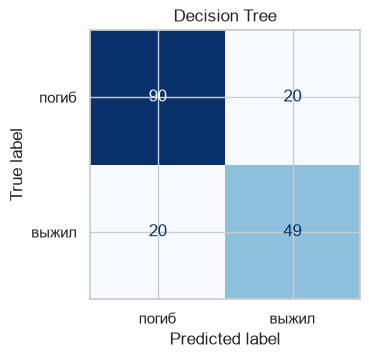

In [12]:
dt = make_model(DecisionTreeClassifier(random_state=RANDOM_STATE))   # параметры по умолчанию
dt.fit(X_train, y_train)
evaluate("Decision Tree", dt)

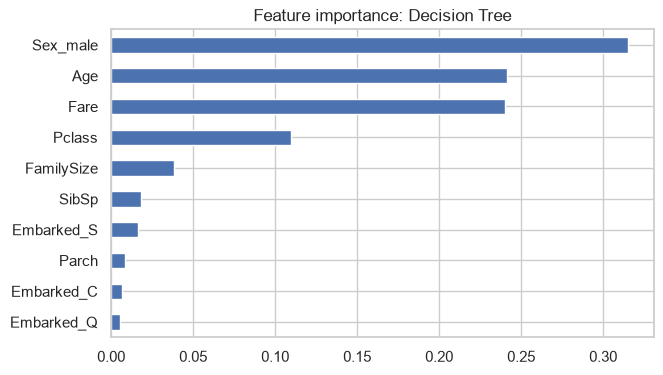

Sex_male      0.315
Age           0.242
Fare          0.240
Pclass        0.110
FamilySize    0.038
SibSp         0.018
Embarked_S    0.016
Parch         0.008
Embarked_C    0.007
Embarked_Q    0.006
dtype: float64

In [13]:
feature_names = dt.named_steps["prep"].get_feature_names_out()
dt_imp = pd.Series(dt.named_steps["model"].feature_importances_, index=feature_names).sort_values()
dt_imp.plot(kind="barh", figsize=(7, 4))
plt.title("Feature importance: Decision Tree")
plt.show()
dt_imp.sort_values(ascending=False).round(3)

**Вывод.**
- На train дерево почти идеально, а на test заметно хуже. Это **переобучение**: дерево без ограничений растёт, пока не запомнит каждого пассажира.
- Порог дерево проходит, но еле-еле.
- Самые важные признаки: пол, затем возраст и цена билета.

## 6. Random Forest (случайный лес)

Random Forest {'Accuracy': 0.81, 'Precision': 0.778, 'Recall': 0.71, 'F1': 0.742, 'F1 train': 0.978}

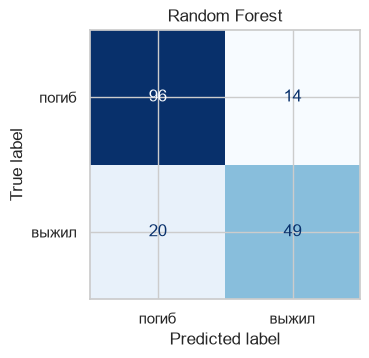

In [14]:
rf = make_model(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
rf.fit(X_train, y_train)
evaluate("Random Forest", rf)

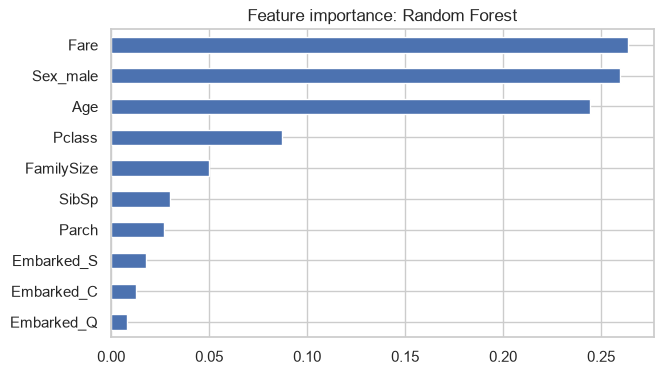

Fare          0.264
Sex_male      0.260
Age           0.244
Pclass        0.087
FamilySize    0.050
SibSp         0.030
Parch         0.027
Embarked_S    0.018
Embarked_C    0.013
Embarked_Q    0.008
dtype: float64

In [15]:
rf_imp = pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names)
rf_imp.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Feature importance: Random Forest")
plt.show()
rf_imp.sort_values(ascending=False).round(3)

**Вывод.**
- Лес лучше одного дерева: много деревьев «голосуют», и их случайные ошибки взаимно гасятся.
- Главная тройка та же, что у дерева: пол, цена билета, возраст. Но у леса они почти одинаково важны, а у дерева пол заметно впереди.

## 7. Gradient Boosting (градиентный бустинг)

Gradient Boosting {'Accuracy': 0.81, 'Precision': 0.83, 'Recall': 0.638, 'F1': 0.721, 'F1 train': 0.872}

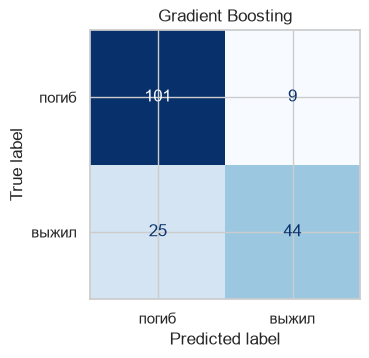

In [16]:
gb = make_model(GradientBoostingClassifier(random_state=RANDOM_STATE))
gb.fit(X_train, y_train)
evaluate("Gradient Boosting", gb)

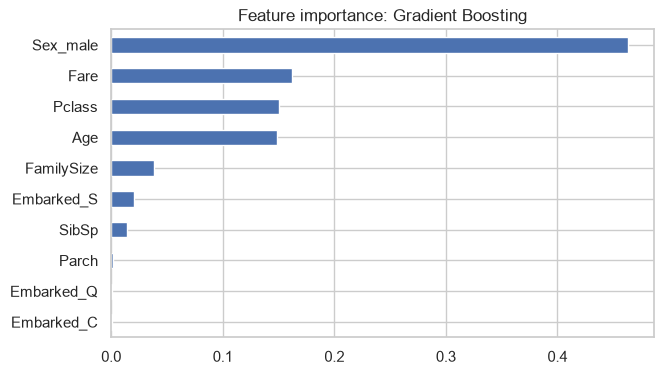

Sex_male      0.463
Fare          0.162
Pclass        0.150
Age           0.148
FamilySize    0.038
Embarked_S    0.021
SibSp         0.014
Parch         0.002
Embarked_Q    0.001
Embarked_C    0.000
dtype: float64

In [17]:
gb_imp = pd.Series(gb.named_steps["model"].feature_importances_, index=feature_names)
gb_imp.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Feature importance: Gradient Boosting")
plt.show()
gb_imp.sort_values(ascending=False).round(3)

**Вывод.**
- Бустинг по качеству близок к лесу (F1 чуть ниже). Переобучается он меньше (разница train/test меньше), потому что строит маленькие деревья.
- У бустинга высокий Precision, но низкий Recall: он осторожно говорит «выжил» и поэтому пропускает часть выживших.
- Бустинг ещё сильнее опирается на пол, чем лес. Остальные важные признаки — класс, цена, возраст.

## 8. SVM (метод опорных векторов)

SVM {'Accuracy': 0.821, 'Precision': 0.803, 'Recall': 0.71, 'F1': 0.754, 'F1 train': 0.775}

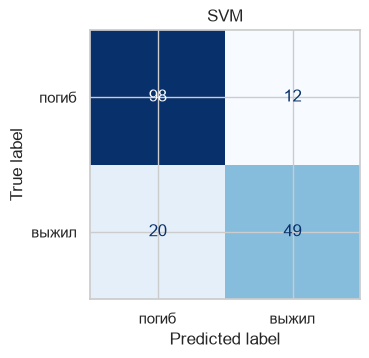

In [18]:
svm = make_model(SVC(random_state=RANDOM_STATE))   # внутри make_model уже есть масштабирование
svm.fit(X_train, y_train)
evaluate("SVM", svm)

In [19]:
# Для сравнения: тот же SVM без масштабирования числовых признаков
preprocess_raw = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), cat_features),
])
svm_raw = Pipeline([("prep", preprocess_raw), ("model", SVC(random_state=RANDOM_STATE))]).fit(X_train, y_train)
print("SVM без масштабирования: F1 =", round(f1_score(y_test, svm_raw.predict(X_test)), 3))

SVM без масштабирования: F1 = 0.323

**Вывод.**
- SVM ищет границу между классами с максимальным «зазором», а зазор измеряется расстоянием. Если не масштабировать, признаки с большими числами (цена билета, возраст) задавят признаки вроде пола (0 или 1).
- Без масштабирования F1 падает очень сильно. Масштабирование для SVM **обязательно**.
- С масштабированием SVM показал хороший результат.

## 9. KNN (k ближайших соседей)

KNN {'Accuracy': 0.799, 'Precision': 0.77, 'Recall': 0.681, 'F1': 0.723, 'F1 train': 0.783}

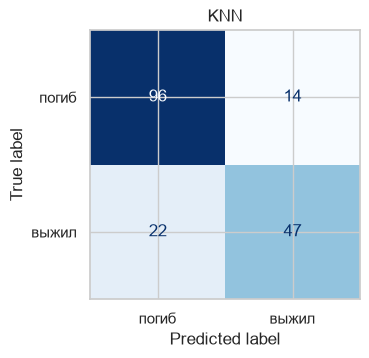

KNN без масштабирования: F1 = 0.602

In [20]:
knn = make_model(KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)
evaluate("KNN", knn)

knn_raw = Pipeline([("prep", preprocess_raw), ("model", KNeighborsClassifier(n_neighbors=5))]).fit(X_train, y_train)
print("KNN без масштабирования: F1 =", round(f1_score(y_test, knn_raw.predict(X_test)), 3))

**Вывод.**
- KNN смотрит на 5 самых похожих пассажиров из train и выбирает ответ большинством. «Похожесть» — это расстояние.
- Без масштабирования расстояние почти полностью определяется ценой билета, потому что у неё самые большие числа. Пол почти не влияет, и качество падает.
- С масштабированием KNN проходит порог.

## 10. Итоговое сравнение (leaderboard)

In [21]:
res = pd.DataFrame(results).T.sort_values("F1", ascending=False)
res["F1 > 0.70"] = res["F1"] > 0.70
res.round(3)

,Accuracy,Precision,Recall,F1,F1 train,F1 > 0.70
SVM,0.821,0.803,0.710,0.754,0.775,True
Random Forest,0.810,0.778,0.710,0.742,0.978,True
KNN,0.799,0.770,0.681,0.723,0.783,True
Gradient Boosting,0.810,0.830,0.638,0.721,0.872,True
Decision Tree,0.777,0.710,0.710,0.710,0.978,True
Baseline (most frequent),0.615,0.000,0.000,0.000,0.000,False


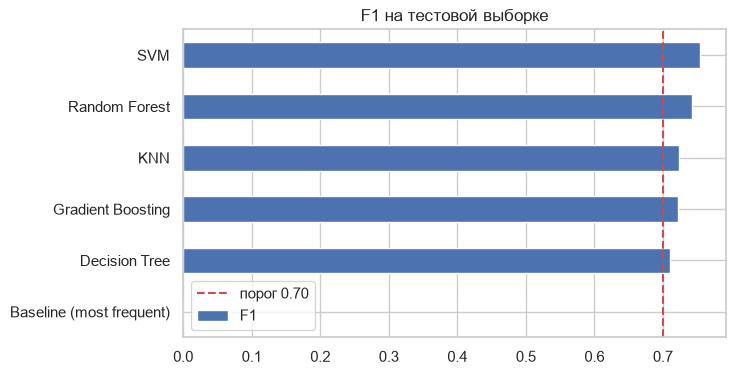

In [22]:
res["F1"].sort_values().plot(kind="barh", figsize=(7, 4))
plt.axvline(0.70, color="r", ls="--", label="порог 0.70")
plt.title("F1 на тестовой выборке"); plt.legend()
plt.show()

**Вывод.**
- Все пять моделей лучше baseline и проходят порог F1 > 0.70.
- Лучше всех SVM, затем Random Forest. Одно дерево — хуже всех, потому что переобучается.
- Модели на деревьях (дерево, лес) на train почти идеальны, а на test хуже — они склонны запоминать данные.
- Разница между моделями небольшая: данных мало, и главную информацию (пол, класс) находят все модели.

## 11. Сравнение feature importance

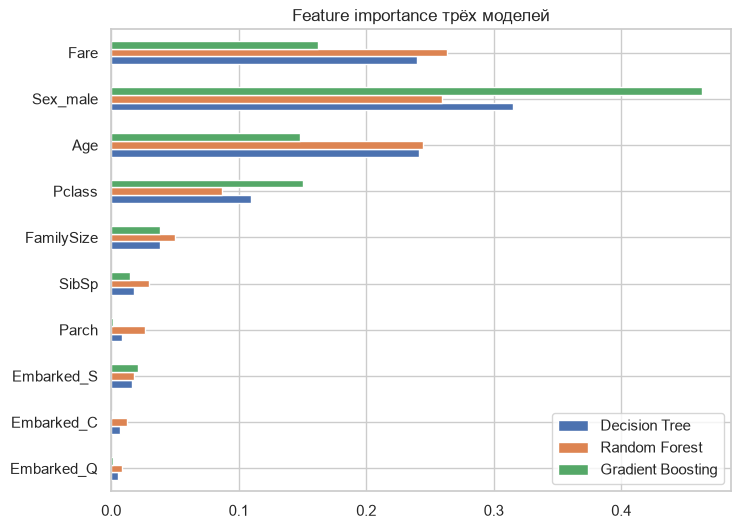

,Decision Tree,Random Forest,Gradient Boosting
Fare,0.240,0.264,0.162
Sex_male,0.315,0.260,0.463
Age,0.242,0.244,0.148
Pclass,0.110,0.087,0.150
FamilySize,0.038,0.050,0.038
SibSp,0.018,0.030,0.014
Parch,0.008,0.027,0.002
Embarked_S,0.016,0.018,0.021
Embarked_C,0.007,0.013,0.000
Embarked_Q,0.006,0.008,0.001


In [23]:
imp = pd.DataFrame({"Decision Tree": dt_imp, "Random Forest": rf_imp, "Gradient Boosting": gb_imp})
imp = imp.sort_values("Random Forest")
imp.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance трёх моделей")
plt.show()
imp.sort_values("Random Forest", ascending=False).round(3)

**Вывод.**
- У всех трёх моделей на первом месте **пол** — как мы и видели в анализе данных.
- Дальше идут цена билета, возраст и класс. Это тоже совпадает с анализом: богатые и дети выживали чаще.
- Порт посадки почти не важен.
- `Fare` и `Pclass` говорят почти одно и то же (дорогой билет = высокий класс), поэтому модели делят важность между ними.

**Можно ли сказать, что важный признак — причина выживания?** Нет. Важность показывает только, что модель
**пользуется** признаком для предсказания. Например, цена билета сама никого не спасла: просто пассажиры
дорогих кают жили ближе к палубе со шлюпками. Связь ≠ причина.

## 12. Анализ ошибок лучшей модели

In [24]:
best_name = res.index[0]
models = {"Decision Tree": dt, "Random Forest": rf, "Gradient Boosting": gb, "SVM": svm, "KNN": knn}
best = models[best_name]
print("Лучшая модель:", best_name)

errors = X_test.copy()
errors["true"] = y_test
errors["pred"] = best.predict(X_test)
errors["error"] = np.where(errors["true"] == errors["pred"], "верно",
                  np.where(errors["pred"] == 1, "FP", "FN"))
errors["error"].value_counts()

Лучшая модель: SVM

error
верно    147
FN        20
FP        12
Name: count, dtype: int64

In [25]:
# Где модель ошибается чаще: доля ошибок по полу и классу
errors["wrong"] = errors["true"] != errors["pred"]
print(errors.groupby("Sex")["wrong"].mean().round(3))
print(errors.groupby("Pclass")["wrong"].mean().round(3))
pd.crosstab([errors["Sex"], errors["Pclass"]], errors["error"])

Sex
female    0.164
male      0.186
Name: wrong, dtype: float64
Pclass
1    0.267
2    0.118
3    0.160
Name: wrong, dtype: float64

error          FN  FP  верно
Sex    Pclass               
female 1        0   1     14
       2        0   1     17
       3        1   7     20
male   1        9   2     19
       2        2   1     13
       3        8   0     64

In [26]:
# Несколько ошибочных пассажиров (добавим имя, чтобы было понятнее, кто это)
wrong = errors[errors["wrong"]].join(df[["Name"]])
wrong[["Name", "Sex", "Age", "Pclass", "Fare", "FamilySize", "true", "pred", "error"]].head(10)

,Name,Sex,Age,Pclass,Fare,FamilySize,true,pred,error
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250,1,1,0,FN
27,"Fortune, Mr. Charles Alexander",male,19.0,1,263.0000,6,0,1,FP
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,35.0,3,20.2500,3,1,0,FN
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,52.0000,2,1,0,FN
455,"Jalsevac, Mr. Ivan",male,29.0,3,7.8958,1,1,0,FN
65,"Moubarek, Master. Gerios",male,NaN,3,15.2458,3,1,0,FN
489,"Coutts, Master. Eden Leslie ""Neville""",male,9.0,3,15.9000,3,1,0,FN
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,4,0,1,FP
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,3,9.4750,2,0,1,FP
564,"Meanwell, Miss. (Marion Ogden)",female,NaN,3,8.0500,1,0,1,FP


**Вывод.**
- FN (выжил, а модель сказала «погиб») встречаются чаще, чем FP. В основном это **мужчины**, которые выжили:
  модель выучила «мужчина — скорее погиб», и выживших мужчин она пропускает.
- FP (погиб, а модель сказала «выжил») — в основном **женщины из 3-го класса**: женщины обычно выживали, но в 3-м классе — только половина.
- Причина ошибок: в данных нет информации, кто где был в момент крушения, кто успел к шлюпке. Модель видит только
  «типичный» случай для пола и класса, а реальная судьба — дело случая.

### Проверка: что будет, если дать модели идентификаторы

In [27]:
# Добавим PassengerId как признак и посмотрим, что сделает Random Forest
X_id = df[num_features + cat_features + ["PassengerId"]]
Xi_train, Xi_test = X_id.loc[X_train.index], X_id.loc[X_test.index]   # то же самое разбиение
prep_id = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_features + ["PassengerId"]),
                             ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                               ("onehot", OneHotEncoder(drop="if_binary"))]), cat_features)],
                            verbose_feature_names_out=False)
rf_id = Pipeline([("prep", prep_id),
                  ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])
rf_id.fit(Xi_train, y_train)
print("RF с PassengerId: F1 test =", round(f1_score(y_test, rf_id.predict(Xi_test)), 3),
      "| без него:", round(results["Random Forest"]["F1"], 3))
pd.Series(rf_id.named_steps["model"].feature_importances_,
          index=rf_id.named_steps["prep"].get_feature_names_out()).sort_values(ascending=False).round(3).head(4)

RF с PassengerId: F1 test = 0.758 | без него: 0.742

Sex_male       0.241
Fare           0.201
PassengerId    0.181
Age            0.165
dtype: float64

**Вывод.** Номер пассажира — это просто порядковый номер, он никак не связан с выживанием. Но лес всё равно
поставил его в число самых важных признаков: по номеру удобно «запоминать» конкретных людей из train.
Качество на test почти не изменилось — это случайность. Полагаться на такой признак нельзя. Поэтому идентификаторы (`PassengerId`, `Name`, `Ticket`, `Cabin`) мы правильно выкинули,
и наше качество не связано с запоминанием пассажиров.

## 13. Итоговые выводы

- Задача: предсказать, выжил ли пассажир Титаника. Главная метрика — F1 для выживших.
- Baseline («все погибли») даёт неплохую Accuracy, но F1 = 0 — поэтому одной Accuracy верить нельзя.
- Все 5 моделей проходят порог F1 > 0.70. Лучшие — SVM и Random Forest, хуже всех — одиночное дерево (переобучается).
- Для SVM и KNN обязательно масштабирование: без него качество сильно падает.
- Самый важный признак у всех моделей — пол, дальше цена билета, возраст и класс. Это связь, а не причина.
- Модель чаще всего ошибается на «нетипичных» пассажирах: выживших мужчинах и погибших женщинах из 3-го класса.
- Идентификаторы пассажиров выкинули, чтобы модель не запоминала конкретных людей.